# Dia 24 — Classes Abstratas (ABC) e Protocols em Python para Data Science

**Fase 1 — Fundamentos de Python** · 23/11/2026 · Gutemberg Rapôso

> Linguística + Data Science + NLP aplicado à educação

### Objetivos de aprendizagem

Ao final deste notebook, eu devo ser capaz de:

1. Usar o módulo `abc` (`ABC`, `ABCMeta`, `@abstractmethod`) e entender por que `abstractproperty` está **depreciado**.
2. Explicar por que interfaces explícitas importam em DS: transformadores, validadores, métricas e carregadores de dados.
3. Implementar um `DataTransformer` abstrato (StandardScaler-like e MinMax-like) e conferir os resultados com o scikit-learn no **iris**.
4. Construir um `TextProcessor` abstrato (normalizador, tokenizador, removedor de stopwords) para um corpus educacional real.
5. Diferenciar **subtipagem nominal** (herança) de **subtipagem estrutural** (`typing.Protocol`, PEP 544).
6. Usar `@runtime_checkable` com `isinstance()` — e conhecer suas limitações.
7. Implementar métricas (`Accuracy`, `F1`, `RMSE`) como classes concretas no **breast_cancer**.
8. Criar `DataLoader`s (CSV, JSON, Seaborn) com validação compartilhada.
9. Combinar ABCs + Protocols num pipeline de NLP *type-safe* para textos educacionais.
10. Usar `__subclasshook__` e `register()` para subclasses virtuais.
11. Decidir entre ABC, Protocol e duck typing.

**Dados utilizados (todos públicos):** `sklearn.datasets` (`load_iris`, `load_breast_cancer`, `load_wine`, `load_diabetes`, `load_digits`), `seaborn` (`tips`, `penguins`) e `statsmodels.datasets` (documentação `DESCR` usada como corpus).

In [1]:
# Core imports used throughout the notebook
from __future__ import annotations

import inspect
import json
import re
import string
import sys
import tempfile
import unicodedata
from abc import ABC, ABCMeta, abstractmethod
from collections import Counter
from collections.abc import Iterable, Mapping, Sequence, Sized
from pathlib import Path
from typing import Any, Generic, Protocol, TypeVar, runtime_checkable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import statsmodels
import statsmodels.api as sm
from sklearn.datasets import (load_breast_cancer, load_diabetes, load_digits,
                              load_iris, load_wine)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# get_protocol_members exists in typing from Python 3.13; fall back gracefully
try:
    from typing import get_protocol_members
except ImportError:  # pragma: no cover - depends on Python version
    try:
        from typing_extensions import get_protocol_members
    except ImportError:
        def get_protocol_members(proto: type) -> frozenset[str]:
            """Minimal fallback: public callables/annotations declared on the protocol."""
            names = {n for n in vars(proto) if not n.startswith("_")}
            names |= set(getattr(proto, "__annotations__", {}))
            return frozenset(names)

RANDOM_STATE = 42
pd.set_option("display.precision", 4)
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__}")
print(f"scikit-learn {sklearn.__version__} | seaborn {sns.__version__} | statsmodels {statsmodels.__version__}")

Python 3.11.17 | pandas 2.3.3 | numpy 1.26.4
scikit-learn 1.9.1 | seaborn 0.13.2 | statsmodels 0.15.0


## 1. Introdução às ABCs: o módulo `abc`

Uma **Abstract Base Class (ABC)** define um *contrato*: quais métodos uma subclasse **precisa** implementar.

- `ABC` é uma classe auxiliar cuja metaclasse é `ABCMeta` (`class X(ABC)` ≡ `class X(metaclass=ABCMeta)`).
- `@abstractmethod` marca métodos obrigatórios. Uma classe com qualquer método abstrato não implementado **não pode ser instanciada** → `TypeError`.
- O erro acontece na **instanciação**, não na definição da classe. Isso é importante: o bug aparece cedo, antes de rodar horas de treino.

Analogia linguística: a ABC é como a *gramática* de um gênero textual — um "resumo acadêmico" precisa ter objetivo, método e resultados; cada resumo concreto preenche essas partes do seu jeito.

In [2]:
class CorpusSource(ABC):
    """Abstract contract for anything that yields documents of a corpus."""

    @abstractmethod
    def documents(self) -> list[str]:
        """Return the raw documents."""

    def size(self) -> int:
        """Concrete helper built on top of the abstract method (template-style)."""
        return len(self.documents())


# 1) The ABC itself cannot be instantiated
try:
    CorpusSource()
except TypeError as exc:
    print("TypeError:", exc)


# 2) An incomplete subclass also fails -- at instantiation time, not definition time
class IncompleteSource(CorpusSource):
    pass


try:
    IncompleteSource()
except TypeError as exc:
    print("TypeError:", exc)


# 3) A complete subclass works and inherits the concrete helper
class SklearnDescrSource(CorpusSource):
    """Uses the real DESCR text of scikit-learn datasets as documents."""

    def documents(self) -> list[str]:
        return [load_iris().DESCR, load_wine().DESCR]


src = SklearnDescrSource()
print("Documents:", src.size(), "| abstract methods of base:", CorpusSource.__abstractmethods__)

TypeError: Can't instantiate abstract class CorpusSource with abstract method documents
TypeError: Can't instantiate abstract class IncompleteSource with abstract method documents
Documents: 2 | abstract methods of base: frozenset({'documents'})


### `abstractproperty` (depreciado) vs `@property` + `@abstractmethod`

`abc.abstractproperty`, `abstractclassmethod` e `abstractstaticmethod` estão **depreciados desde o Python 3.3**. A forma moderna é empilhar decoradores, com `@abstractmethod` **sempre como o mais interno** (mais perto da função):

```python
@property
@abstractmethod
def name(self) -> str: ...
```

Isso também vale para `@classmethod` e `@staticmethod`.

In [3]:
import abc

print("abc.abstractproperty still exists (deprecated):", hasattr(abc, "abstractproperty"))


class ModelCard(ABC):
    """Abstract documentation card every model must provide."""

    @property
    @abstractmethod
    def name(self) -> str:
        """Human-readable model name."""

    @property
    @abstractmethod
    def task(self) -> str:
        """'classification' or 'regression'."""

    @classmethod
    @abstractmethod
    def from_dict(cls, payload: Mapping[str, Any]) -> "ModelCard":
        """Alternative constructor every card must support."""

    def describe(self) -> str:
        return f"{self.name} ({self.task})"


class IrisCard(ModelCard):
    def __init__(self, name: str, task: str) -> None:
        self._name, self._task = name, task

    @property
    def name(self) -> str:
        return self._name

    @property
    def task(self) -> str:
        return self._task

    @classmethod
    def from_dict(cls, payload: Mapping[str, Any]) -> "IrisCard":
        return cls(payload["name"], payload["task"])


card = IrisCard.from_dict({"name": "Iris LogReg", "task": "classification"})
print(card.describe())
print("Abstract members of ModelCard:", sorted(ModelCard.__abstractmethods__))

abc.abstractproperty still exists (deprecated): True
Iris LogReg (classification)
Abstract members of ModelCard: ['from_dict', 'name', 'task']


## 2. Por que ABCs importam em Data Science

Em projetos reais, vários componentes precisam ter **a mesma interface** para serem intercambiáveis:

| Componente | Contrato típico | Exemplo no scikit-learn |
|---|---|---|
| Transformador | `fit(X)`, `transform(X)` | `StandardScaler`, `TfidfVectorizer` |
| Modelo | `fit(X, y)`, `predict(X)` | `LogisticRegression` |
| Métrica | `__call__(y_true, y_pred)` | `accuracy_score` |
| Validador | `validate(df) -> erros` | — |
| Carregador | `load() -> DataFrame` | — |

Sem um contrato, um colega pode criar um transformador com `apply()` em vez de `transform()`, e o erro só aparece no meio do pipeline. Com ABC, o erro aparece na criação do objeto.

A própria biblioteca padrão usa ABCs em `collections.abc` — e elas funcionam com tipos que **nem herdam** delas (graças a `__subclasshook__`, que veremos na seção 11).

In [4]:
# collections.abc: the standard library's own ABCs
iris_df = load_iris(as_frame=True).frame
checks = {
    "list is Sequence": isinstance([1, 2], Sequence),
    "str is Sequence": isinstance("corpus", Sequence),
    "dict is Mapping": isinstance({"a": 1}, Mapping),
    "DataFrame is Sized": isinstance(iris_df, Sized),
    "DataFrame is Iterable": isinstance(iris_df, Iterable),
    "ndarray is Sequence": isinstance(np.arange(3), Sequence),  # False: not registered
}
pd.Series(checks, name="result").to_frame()

,result
list is Sequence,True
str is Sequence,True
dict is Mapping,True
DataFrame is Sized,True
DataFrame is Iterable,True
ndarray is Sequence,False


**Observação:** `np.ndarray` é iterável e tem tamanho, mas **não** é registrado como `Sequence`. Isso mostra a diferença entre "ter os métodos" e "ter declarado o contrato" — o tema central deste notebook.

## 3. Exemplo concreto: `DataTransformer` abstrato (dataset iris)

Vou criar uma ABC com:
- métodos abstratos `_fit` e `_transform` (o "miolo" que cada subclasse implementa);
- métodos concretos `fit`, `transform`, `fit_transform` e `inverse_transform` que fazem **validação comum** (padrão *Template Method*).

In [5]:
class NotFittedError(RuntimeError):
    """Raised when transform is called before fit."""


class DataTransformer(ABC):
    """Abstract base class for numeric column-wise transformers.

    Subclasses implement ``_fit`` and ``_transform`` (and optionally
    ``_inverse_transform``); the public API handles validation.
    """

    def __init__(self) -> None:
        self.is_fitted_: bool = False
        self.n_features_in_: int | None = None

    # ---- public, concrete API -------------------------------------------
    def fit(self, X: np.ndarray | pd.DataFrame) -> "DataTransformer":
        X_arr = self._validate(X, fitting=True)
        self._fit(X_arr)
        self.is_fitted_ = True
        return self

    def transform(self, X: np.ndarray | pd.DataFrame) -> np.ndarray:
        if not self.is_fitted_:
            raise NotFittedError(f"{type(self).__name__} must be fitted first.")
        return self._transform(self._validate(X, fitting=False))

    def fit_transform(self, X: np.ndarray | pd.DataFrame) -> np.ndarray:
        return self.fit(X).transform(X)

    def inverse_transform(self, X: np.ndarray) -> np.ndarray:
        if not self.is_fitted_:
            raise NotFittedError(f"{type(self).__name__} must be fitted first.")
        return self._inverse_transform(np.asarray(X, dtype=float))

    # ---- abstract hooks ---------------------------------------------------
    @abstractmethod
    def _fit(self, X: np.ndarray) -> None:
        """Learn parameters from X."""

    @abstractmethod
    def _transform(self, X: np.ndarray) -> np.ndarray:
        """Apply learned parameters to X."""

    def _inverse_transform(self, X: np.ndarray) -> np.ndarray:
        raise NotImplementedError(f"{type(self).__name__} is not invertible.")

    # ---- shared validation -------------------------------------------------
    def _validate(self, X: np.ndarray | pd.DataFrame, fitting: bool) -> np.ndarray:
        X_arr = np.asarray(X, dtype=float)
        if X_arr.ndim != 2:
            raise ValueError(f"Expected 2D input, got shape {X_arr.shape}.")
        if np.isnan(X_arr).any():
            raise ValueError("Input contains NaN values.")
        if fitting:
            self.n_features_in_ = X_arr.shape[1]
        elif X_arr.shape[1] != self.n_features_in_:
            raise ValueError(f"Expected {self.n_features_in_} features, got {X_arr.shape[1]}.")
        return X_arr

    def __repr__(self) -> str:
        return f"{type(self).__name__}(fitted={self.is_fitted_})"

In [6]:
class StandardScalerLike(DataTransformer):
    """z-score scaling: (x - mean) / std (population std, like scikit-learn)."""

    def _fit(self, X: np.ndarray) -> None:
        self.mean_ = X.mean(axis=0)
        std = X.std(axis=0)
        self.scale_ = np.where(std == 0, 1.0, std)  # avoid division by zero

    def _transform(self, X: np.ndarray) -> np.ndarray:
        return (X - self.mean_) / self.scale_

    def _inverse_transform(self, X: np.ndarray) -> np.ndarray:
        return X * self.scale_ + self.mean_


class MinMaxScalerLike(DataTransformer):
    """Rescale each feature to the [feature_min, feature_max] range."""

    def __init__(self, feature_range: tuple[float, float] = (0.0, 1.0)) -> None:
        super().__init__()
        self.feature_range = feature_range

    def _fit(self, X: np.ndarray) -> None:
        self.data_min_ = X.min(axis=0)
        span = X.max(axis=0) - self.data_min_
        self.data_range_ = np.where(span == 0, 1.0, span)

    def _transform(self, X: np.ndarray) -> np.ndarray:
        lo, hi = self.feature_range
        return (X - self.data_min_) / self.data_range_ * (hi - lo) + lo

    def _inverse_transform(self, X: np.ndarray) -> np.ndarray:
        lo, hi = self.feature_range
        return (X - lo) / (hi - lo) * self.data_range_ + self.data_min_


class LogTransformer(DataTransformer):
    """log1p transform for non-negative skewed features (not invertible here on purpose)."""

    def _fit(self, X: np.ndarray) -> None:
        if (X < 0).any():
            raise ValueError("LogTransformer requires non-negative values.")

    def _transform(self, X: np.ndarray) -> np.ndarray:
        return np.log1p(X)

In [7]:
iris = load_iris(as_frame=True)
X_iris = iris.data
X_train, X_test = train_test_split(X_iris, test_size=0.3, random_state=RANDOM_STATE, stratify=iris.target)

pairs = [
    (StandardScalerLike(), StandardScaler()),
    (MinMaxScalerLike(), MinMaxScaler()),
    (MinMaxScalerLike((-1, 1)), MinMaxScaler(feature_range=(-1, 1))),
]
rows = []
for ours, ref in pairs:
    ours.fit(X_train)
    ref.fit(X_train.values)
    out_ours, out_ref = ours.transform(X_test), ref.transform(X_test.values)
    rows.append({
        "transformer": f"{type(ours).__name__}{getattr(ours, 'feature_range', '')}",
        "matches_sklearn": np.allclose(out_ours, out_ref),
        "roundtrip_ok": np.allclose(ours.inverse_transform(out_ours), X_test.values),
        "test_min": out_ours.min().round(3),
        "test_max": out_ours.max().round(3),
    })
pd.DataFrame(rows)

,transformer,matches_sklearn,roundtrip_ok,test_min,test_max
0,StandardScalerLike,True,True,-1.716,2.076
1,"MinMaxScalerLike(0.0, 1.0)",True,True,-0.017,0.958
2,"MinMaxScalerLike(-1, 1)",True,True,-1.034,0.917


In [8]:
# The shared validation in the base class protects every subclass
scaler = StandardScalerLike()
errors = {}
for label, action in {
    "transform before fit": lambda: scaler.transform(X_test),
    "1D input": lambda: StandardScalerLike().fit(X_iris.iloc[:, 0]),
    "wrong n_features": lambda: StandardScalerLike().fit(X_train).transform(X_test.iloc[:, :2]),
    "not invertible": lambda: LogTransformer().fit(X_train).inverse_transform(X_test),
}.items():
    try:
        action()
    except (NotFittedError, ValueError, NotImplementedError) as exc:
        errors[label] = f"{type(exc).__name__}: {exc}"
pd.Series(errors, name="error").to_frame()

,error
transform before fit,NotFittedError: StandardScalerLike must be fit...
1D input,"ValueError: Expected 2D input, got shape (150,)."
wrong n_features,"ValueError: Expected 4 features, got 2."
not invertible,NotImplementedError: LogTransformer is not inv...


**O que aprendi:** os três transformadores reproduzem o scikit-learn (`matches_sklearn = True`) e toda a validação (NaN, dimensão, número de features, ordem fit→transform) foi escrita **uma única vez** na classe base. As subclasses só implementam a matemática.

## 4. `TextProcessor` abstrato: processamento de texto para NLP

Agora um caso mais próximo da minha área. Como corpus, uso a **documentação real (`DESCR`)** de datasets públicos do scikit-learn e do statsmodels — textos técnico-didáticos em inglês, que servem bem como material de leitura para aprendizes de inglês acadêmico (sem necessidade de downloads extras do NLTK).

Uso `Generic[InT, OutT]` para que cada processador declare **o tipo de entrada e de saída**: o normalizador vai de `str` para `str`, o tokenizador de `str` para `list[str]`, e o removedor de stopwords de `list[str]` para `list[str]`.

In [9]:
def clean_descr(text: str) -> str:
    """Drop RST tables/markup lines from a dataset DESCR, keeping prose."""
    keep = []
    for line in text.splitlines():
        s = line.strip()
        is_table_row = re.search(r"\S\s{2,}\S", s) is not None  # column-aligned table text
        if not s or is_table_row or set(s) <= set("=-:*|.+_ ") or s.startswith((":", "..", "|", "-", "*", "=")):
            continue
        keep.append(s)
    return " ".join(keep)


sk_loaders = {"iris": load_iris, "wine": load_wine, "breast_cancer": load_breast_cancer,
              "diabetes": load_diabetes, "digits": load_digits}
sm_modules = {"star98": sm.datasets.star98, "scotland": sm.datasets.scotland,
              "co2": sm.datasets.co2, "committee": sm.datasets.committee,
              "cpunish": sm.datasets.cpunish}

corpus = {f"sklearn/{k}": clean_descr(f().DESCR) for k, f in sk_loaders.items()}
corpus |= {f"statsmodels/{k}": clean_descr(m.DESCRLONG) for k, m in sm_modules.items()}

corpus_df = pd.DataFrame({"doc_id": list(corpus), "text": list(corpus.values())})
corpus_df["n_chars"] = corpus_df["text"].str.len()
print(f"{len(corpus_df)} documents, {corpus_df['n_chars'].sum():,} characters")
corpus_df[["doc_id", "n_chars"]].assign(preview=corpus_df["text"].str[:70] + "...")

10 documents, 8,925 characters


,doc_id,n_chars,preview
0,sklearn/iris,756,"Iris plants dataset The famous Iris database, ..."
1,sklearn/wine,1609,Wine recognition dataset This is a copy of UCI...
2,sklearn/breast_cancer,1585,Breast cancer Wisconsin (diagnostic) dataset T...
3,sklearn/diabetes,787,"Diabetes dataset Ten baseline variables, age, ..."
4,sklearn/digits,1342,Optical recognition of handwritten digits data...
5,statsmodels/star98,349,This data is on the California education polic...
6,statsmodels/scotland,654,This data is based on the example in Gill and ...
7,statsmodels/co2,721,Atmospheric CO2 from Continuous Air Samples at...
8,statsmodels/committee,637,"The example in Gill, seeks to explain the numb..."
9,statsmodels/cpunish,485,This data describes the number of times capita...


In [10]:
InT = TypeVar("InT")
OutT = TypeVar("OutT")


class TextProcessor(ABC, Generic[InT, OutT]):
    """Abstract text-processing step with typed input and output."""

    input_type: type = object
    output_type: type = object

    @abstractmethod
    def process(self, data: InT) -> OutT:
        """Transform one document representation into another."""

    def __call__(self, data: InT) -> OutT:
        if not isinstance(data, self.input_type):
            raise TypeError(f"{type(self).__name__} expects {self.input_type.__name__}, "
                            f"got {type(data).__name__}.")
        return self.process(data)

    def batch(self, items: Iterable[InT]) -> list[OutT]:
        return [self(item) for item in items]


class TextNormalizer(TextProcessor[str, str]):
    """Lowercase, strip accents, collapse whitespace."""

    input_type = output_type = str

    def __init__(self, strip_accents: bool = True) -> None:
        self.strip_accents = strip_accents

    def process(self, data: str) -> str:
        text = data.lower()
        if self.strip_accents:
            text = "".join(c for c in unicodedata.normalize("NFKD", text) if not unicodedata.combining(c))
        return re.sub(r"\s+", " ", text).strip()


class RegexTokenizer(TextProcessor[str, list]):
    """Alphabetic tokenizer that keeps internal apostrophes/hyphens (e.g. "don't", "well-known")."""

    input_type, output_type = str, list
    pattern = re.compile(r"[a-z]+(?:['-][a-z]+)*")

    def process(self, data: str) -> list[str]:
        return self.pattern.findall(data)


class StopwordRemover(TextProcessor[list, list]):
    """Remove function words; the list is a small, hand-written English set."""

    input_type = output_type = list
    DEFAULT_STOPWORDS = frozenset(
        "a an the and or but if of to in on at by for with from as is are was were be been "
        "being this that these those it its which who whom there their they them he she we you "
        "i not no can will would should may might has have had do does did so than then such "
        "into also each other more most some any all one two".split()
    )

    def __init__(self, stopwords: Iterable[str] | None = None, min_len: int = 2) -> None:
        self.stopwords = frozenset(stopwords) if stopwords is not None else self.DEFAULT_STOPWORDS
        self.min_len = min_len

    def process(self, data: list[str]) -> list[str]:
        return [t for t in data if t not in self.stopwords and len(t) >= self.min_len]


# TextProcessor itself is abstract
try:
    TextProcessor()
except TypeError as exc:
    print("TypeError:", exc)

# The base __call__ enforces the declared input type
try:
    StopwordRemover()("a raw string instead of tokens")
except TypeError as exc:
    print("TypeError:", exc)

TypeError: Can't instantiate abstract class TextProcessor with abstract method process
TypeError: StopwordRemover expects list, got str.


In [11]:
normalizer, tokenizer, remover = TextNormalizer(), RegexTokenizer(), StopwordRemover()

def run_steps(text: str) -> list[str]:
    return remover(tokenizer(normalizer(text)))

corpus_df["tokens_all"] = corpus_df["text"].map(lambda t: tokenizer(normalizer(t)))
corpus_df["tokens"] = corpus_df["text"].map(run_steps)
stats = pd.DataFrame({
    "doc_id": corpus_df["doc_id"],
    "n_tokens": corpus_df["tokens_all"].str.len(),
    "n_content": corpus_df["tokens"].str.len(),
    "n_types": corpus_df["tokens"].map(lambda ts: len(set(ts))),
})
stats["stopword_share"] = 1 - stats["n_content"] / stats["n_tokens"]
stats["ttr_content"] = stats["n_types"] / stats["n_content"]
print("Example:", run_steps("The Iris dataset is a well-known, classic dataset for teaching!"))
stats.sort_values("n_tokens", ascending=False)

Example: ['iris', 'dataset', 'well-known', 'classic', 'dataset', 'teaching']


,doc_id,n_tokens,n_content,n_types,stopword_share,ttr_content
1,sklearn/wine,226,156,105,0.3097,0.6731
2,sklearn/breast_cancer,219,152,115,0.3059,0.7566
4,sklearn/digits,200,124,97,0.3800,0.7823
3,sklearn/diabetes,118,83,75,0.2966,0.9036
0,sklearn/iris,115,67,61,0.4174,0.9104
7,statsmodels/co2,113,74,60,0.3451,0.8108
8,statsmodels/committee,108,58,37,0.4630,0.6379
6,statsmodels/scotland,99,62,56,0.3737,0.9032
9,statsmodels/cpunish,78,42,37,0.4615,0.8810
5,statsmodels/star98,56,36,33,0.3571,0.9167


**Nota metodológica:** a *type-token ratio* (TTR) depende fortemente do tamanho do texto (textos maiores tendem a ter TTR menor), então ela **não** deve ser usada para comparar documentos de tamanhos tão diferentes sem normalização (ex.: MATTR ou amostras de tamanho fixo). Aqui ela serve só para ilustrar os processadores.

## 5. Protocols (PEP 544): subtipagem estrutural vs nominal

- **Subtipagem nominal**: `B` é subtipo de `A` porque **declarou** `class B(A)`. É o que as ABCs fazem.
- **Subtipagem estrutural**: `B` é subtipo de `A` se **tem a mesma forma** (os mesmos métodos/atributos), sem herdar nada. É o "duck typing" formalizado para checadores estáticos (mypy, pyright).

`typing.Protocol` (Python 3.8+) permite descrever essa "forma". A grande vantagem: classes de **terceiros** (scikit-learn, spaCy...) satisfazem o protocolo sem que eu precise modificá-las.

Analogia sociolinguística: nominal é como reconhecer um falante como "professor" pelo diploma; estrutural é reconhecê-lo pelo que ele **faz** (explica, corrige, avalia).

In [12]:
class HasVocabulary(Protocol):
    """Anything that exposes a vocabulary and its size."""

    vocabulary: set[str]

    def vocab_size(self) -> int: ...


class LearnerText:
    """Does NOT inherit from HasVocabulary -- it just has the right shape."""

    def __init__(self, text: str) -> None:
        self.vocabulary = set(run_steps(text))

    def vocab_size(self) -> int:
        return len(self.vocabulary)


def lexical_overlap(a: HasVocabulary, b: HasVocabulary) -> float:
    """Jaccard overlap between two vocabularies (statically type-checked via the protocol)."""
    union = a.vocabulary | b.vocabulary
    return len(a.vocabulary & b.vocabulary) / len(union) if union else 0.0


iris_text = LearnerText(corpus["sklearn/iris"])
wine_text = LearnerText(corpus["sklearn/wine"])
print("LearnerText inherits HasVocabulary?", HasVocabulary in LearnerText.__mro__)
print(f"Vocab sizes: iris={iris_text.vocab_size()}, wine={wine_text.vocab_size()}")
print(f"Jaccard overlap iris vs wine: {lexical_overlap(iris_text, wine_text):.3f}")
print("Protocol members:", sorted(get_protocol_members(HasVocabulary)))

# A plain (non-runtime_checkable) Protocol cannot be used with isinstance
try:
    isinstance(iris_text, HasVocabulary)
except TypeError as exc:
    print("TypeError:", exc)

LearnerText inherits HasVocabulary? False
Vocab sizes: iris=61, wine=105
Jaccard overlap iris vs wine: 0.107
Protocol members: ['vocab_size', 'vocabulary']
TypeError: Instance and class checks can only be used with @runtime_checkable protocols


## 6. Protocols para componentes de pipeline de ML: `Fittable`, `Transformable`, `Scorable`

Vou descrever as "formas" mínimas dos componentes de ML. Protocols podem ser **compostos** por herança entre protocolos (`class FitTransformer(Fittable, Transformable, Protocol)`).

In [13]:
@runtime_checkable
class Fittable(Protocol):
    def fit(self, X: Any, y: Any = None) -> Any: ...


@runtime_checkable
class Transformable(Protocol):
    def transform(self, X: Any) -> Any: ...


@runtime_checkable
class Predictor(Protocol):
    def predict(self, X: Any) -> Any: ...


@runtime_checkable
class Scorable(Protocol):
    def score(self, X: Any, y: Any) -> float: ...


@runtime_checkable
class FitTransformer(Fittable, Transformable, Protocol):
    """Composite protocol: must have both fit and transform."""


@runtime_checkable
class SupervisedModel(Fittable, Predictor, Scorable, Protocol):
    """Composite protocol for a supervised estimator."""


for proto in (Fittable, Transformable, Scorable, FitTransformer, SupervisedModel):
    print(f"{proto.__name__:<16} members = {sorted(get_protocol_members(proto))}")

Fittable         members = ['fit']
Transformable    members = ['transform']
Scorable         members = ['score']
FitTransformer   members = ['fit', 'transform']
SupervisedModel  members = ['fit', 'predict', 'score']


In [14]:
def preprocess(step: FitTransformer, X_tr: Any, X_te: Any) -> tuple[np.ndarray, np.ndarray]:
    """Fit on train, transform both splits. Works for ANY object with fit + transform."""
    step.fit(X_tr)
    return np.asarray(step.transform(X_tr)), np.asarray(step.transform(X_te))


def evaluate(model: SupervisedModel, X_tr: Any, y_tr: Any, X_te: Any, y_te: Any) -> float:
    """Fit and score any supervised model that matches the protocol."""
    model.fit(X_tr, y_tr)
    return float(model.score(X_te, y_te))


y = iris.target
Xtr, Xte, ytr, yte = train_test_split(X_iris, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

results = []
# Our ABC-based transformers and scikit-learn's classes both satisfy FitTransformer
for step in (StandardScalerLike(), MinMaxScalerLike(), StandardScaler(), MinMaxScaler()):
    Xtr_s, Xte_s = preprocess(step, Xtr, Xte)
    acc = evaluate(LogisticRegression(max_iter=1000), Xtr_s, ytr, Xte_s, yte)
    results.append({"preprocessor": type(step).__name__,
                    "origin": type(step).__module__.split(".")[0], "test_accuracy": acc})
pd.DataFrame(results)

,preprocessor,origin,test_accuracy
0,StandardScalerLike,__main__,0.9111
1,MinMaxScalerLike,__main__,0.8667
2,StandardScaler,sklearn,0.9111
3,MinMaxScaler,sklearn,0.8667


Os escaladores "caseiros" (`__main__`) e os do scikit-learn são intercambiáveis porque ambos têm `fit` e `transform` — nenhum deles herda de `FitTransformer`. (Acurácias idênticas são esperadas, pois os escaladores produzem os mesmos valores; trata-se de um único *split*, não de um ranking de métodos.)

## 7. `@runtime_checkable` e `isinstance()`

`@runtime_checkable` permite usar `isinstance(obj, Proto)`. Mas atenção:

- A verificação só confere se os **nomes** dos membros existem (`hasattr`), **não** as assinaturas nem os tipos de retorno.
- Protocols com atributos de dados (não-métodos) não funcionam com `issubclass()`.
- `isinstance` com protocolos é mais lento que com classes comuns — evite em *loops* muito quentes.

In [15]:
candidates = {
    "StandardScaler (sklearn)": StandardScaler(),
    "LogisticRegression (sklearn)": LogisticRegression(),
    "make_pipeline(scaler, logreg)": make_pipeline(StandardScaler(), LogisticRegression()),
    "StandardScalerLike (ours)": StandardScalerLike(),
    "TextNormalizer (ours)": TextNormalizer(),
    "pandas DataFrame": iris_df,
}
protocols = (Fittable, Transformable, Predictor, Scorable, FitTransformer, SupervisedModel)
matrix = pd.DataFrame(
    {p.__name__: [isinstance(obj, p) for obj in candidates.values()] for p in protocols},
    index=list(candidates),
)
matrix

,Fittable,Transformable,Predictor,Scorable,FitTransformer,SupervisedModel
StandardScaler (sklearn),True,True,False,False,True,False
LogisticRegression (sklearn),True,False,True,True,False,True
"make_pipeline(scaler, logreg)",True,True,True,True,True,True
StandardScalerLike (ours),True,True,False,False,True,False
TextNormalizer (ours),False,False,False,False,False,False
pandas DataFrame,False,True,False,False,False,False


In [16]:
# Pitfall: runtime checks only look at NAMES, not signatures or behaviour
class FakeTransformer:
    fit = 42                       # not even callable!

    def transform(self, a, b, c):  # wrong signature
        return "surprise"


fake = FakeTransformer()
print("isinstance(fake, FitTransformer):", isinstance(fake, FitTransformer))  # True!
try:
    preprocess(fake, Xtr, Xte)
except TypeError as exc:
    print("Fails only when used ->", type(exc).__name__, ":", exc)


# A defensive helper: check names AND callability, then optionally the signature
def conforms(obj: Any, proto: type) -> bool:
    """Stricter runtime check: every protocol member must exist and be callable if it is a method."""
    for name in get_protocol_members(proto):
        attr = getattr(obj, name, None)
        expected = getattr(proto, name, None)
        if attr is None or (callable(expected) and not callable(attr)):
            return False
    return True


print("conforms(fake, FitTransformer):", conforms(fake, FitTransformer))
print("conforms(StandardScaler(), FitTransformer):", conforms(StandardScaler(), FitTransformer))

isinstance(fake, FitTransformer): True
Fails only when used -> TypeError : 'int' object is not callable
conforms(fake, FitTransformer): False
conforms(StandardScaler(), FitTransformer): True


## 8. `EvaluationMetric` abstrata: Accuracy, F1 e RMSE (dataset breast_cancer)

Uma métrica precisa saber: seu **nome**, se **maior é melhor** (para seleção de modelos) e como **calcular** o valor. A classe base cuida da validação comum (mesmo tamanho, sem NaN, entradas não vazias).

In [17]:
class EvaluationMetric(ABC):
    """Abstract evaluation metric with shared input validation."""

    @property
    @abstractmethod
    def name(self) -> str:
        """Short metric name."""

    @property
    @abstractmethod
    def greater_is_better(self) -> bool:
        """Direction used for model selection."""

    @abstractmethod
    def compute(self, y_true: np.ndarray, y_pred: np.ndarray) -> float:
        """Compute the metric on validated arrays."""

    def __call__(self, y_true: Sequence[float], y_pred: Sequence[float]) -> float:
        yt, yp = np.asarray(y_true), np.asarray(y_pred)
        if yt.shape != yp.shape:
            raise ValueError(f"Shape mismatch: {yt.shape} vs {yp.shape}.")
        if yt.size == 0:
            raise ValueError("Empty inputs.")
        if np.issubdtype(yp.dtype, np.floating) and np.isnan(yp).any():
            raise ValueError("Predictions contain NaN.")
        return float(self.compute(yt, yp))

    def is_better(self, a: float, b: float) -> bool:
        """Return True if score ``a`` is better than score ``b``."""
        return a > b if self.greater_is_better else a < b

    def __repr__(self) -> str:
        arrow = "↑" if self.greater_is_better else "↓"
        return f"<{self.name} {arrow}>"


class Accuracy(EvaluationMetric):
    name = "accuracy"            # a class attribute satisfies an abstract property
    greater_is_better = True

    def compute(self, y_true, y_pred):
        return np.mean(y_true == y_pred)


class F1Score(EvaluationMetric):
    greater_is_better = True

    def __init__(self, positive_label: int = 1) -> None:
        self.positive_label = positive_label

    @property
    def name(self) -> str:
        return f"f1(pos={self.positive_label})"

    def compute(self, y_true, y_pred):
        pos = self.positive_label
        tp = np.sum((y_pred == pos) & (y_true == pos))
        fp = np.sum((y_pred == pos) & (y_true != pos))
        fn = np.sum((y_pred != pos) & (y_true == pos))
        denom = 2 * tp + fp + fn
        return 2 * tp / denom if denom else 0.0


class RMSE(EvaluationMetric):
    name = "rmse"
    greater_is_better = False

    def compute(self, y_true, y_pred):
        return np.sqrt(np.mean((y_true.astype(float) - y_pred.astype(float)) ** 2))


print([Accuracy(), F1Score(), F1Score(positive_label=0), RMSE()])

[<accuracy ↑>, <f1(pos=1) ↑>, <f1(pos=0) ↑>, <rmse ↓>]


In [18]:
bc = load_breast_cancer()
print("Classes:", dict(zip(range(2), bc.target_names)), "| counts:", np.bincount(bc.target))
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(
    bc.data, bc.target, test_size=0.25, random_state=RANDOM_STATE, stratify=bc.target)

clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xb_tr, yb_tr)
pred = clf.predict(Xb_te)
proba = clf.predict_proba(Xb_te)[:, 1]

reference = {
    "accuracy": accuracy_score(yb_te, pred),
    "f1(pos=1)": f1_score(yb_te, pred, pos_label=1),
    "f1(pos=0)": f1_score(yb_te, pred, pos_label=0),
    # RMSE between labels and predicted probabilities = sqrt(Brier score)
    "rmse": np.sqrt(mean_squared_error(yb_te, proba)),
}
metrics: list[EvaluationMetric] = [Accuracy(), F1Score(1), F1Score(0), RMSE()]
report = pd.DataFrame([
    {"metric": m.name, "ours": m(yb_te, proba if isinstance(m, RMSE) else pred),
     "sklearn": reference[m.name], "greater_is_better": m.greater_is_better}
    for m in metrics
])
report["match"] = np.isclose(report["ours"], report["sklearn"])
report

Classes: {0: 'malignant', 1: 'benign'} | counts: [212 357]


,metric,ours,sklearn,greater_is_better,match
0,accuracy,0.9860,0.9860,True,True
1,f1(pos=1),0.9889,0.9889,True,True
2,f1(pos=0),0.9811,0.9811,True,True
3,rmse,0.1344,0.1344,False,True


In [19]:
# Model selection driven by the metric's declared direction
candidates_C = [0.01, 0.1, 1.0, 10.0]
for metric, use_proba in [(F1Score(0), False), (RMSE(), True)]:
    best_C, best_score = None, None
    for C in candidates_C:
        m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000)).fit(Xb_tr, yb_tr)
        out = m.predict_proba(Xb_te)[:, 1] if use_proba else m.predict(Xb_te)
        score = metric(yb_te, out)
        if best_score is None or metric.is_better(score, best_score):
            best_C, best_score = C, score
    print(f"{metric!r:<16} best C = {best_C:<5} score = {best_score:.4f}")
print("(Selected on a single held-out split for illustration only -- use CV in practice.)")

<f1(pos=0) ↑>    best C = 1.0   score = 0.9811


<rmse ↓>         best C = 1.0   score = 0.1344
(Selected on a single held-out split for illustration only -- use CV in practice.)


## 9. `DataLoader` abstrato: CSV, JSON e Seaborn

Carregar dados parece trivial, mas cada fonte tem detalhes diferentes. A ABC garante que **todos** os carregadores devolvam um `DataFrame` validado (colunas obrigatórias, não vazio) e registrem metadados — independentemente da origem.

In [20]:
class DataLoader(ABC):
    """Template for loaders: subclasses implement ``_read``; ``load`` validates."""

    def __init__(self, required_columns: Sequence[str] = ()) -> None:
        self.required_columns = tuple(required_columns)
        self.metadata: dict[str, Any] = {}

    @property
    @abstractmethod
    def source(self) -> str:
        """Human-readable description of the source."""

    @abstractmethod
    def _read(self) -> pd.DataFrame:
        """Read the raw data."""

    def load(self) -> pd.DataFrame:
        df = self._read()
        if not isinstance(df, pd.DataFrame):
            raise TypeError(f"{type(self).__name__}._read must return a DataFrame.")
        if df.empty:
            raise ValueError(f"{self.source} returned no rows.")
        missing = set(self.required_columns) - set(df.columns)
        if missing:
            raise KeyError(f"{self.source} is missing columns: {sorted(missing)}")
        self.metadata = {"source": self.source, "rows": len(df), "cols": df.shape[1],
                         "missing_cells": int(df.isna().sum().sum())}
        return df


class CSVLoader(DataLoader):
    def __init__(self, path: str | Path, **kwargs: Any) -> None:
        super().__init__(**kwargs)
        self.path = Path(path)

    @property
    def source(self) -> str:
        return f"csv:{self.path.name}"

    def _read(self) -> pd.DataFrame:
        return pd.read_csv(self.path)


class JSONLoader(DataLoader):
    def __init__(self, path: str | Path, orient: str = "records", **kwargs: Any) -> None:
        super().__init__(**kwargs)
        self.path, self.orient = Path(path), orient

    @property
    def source(self) -> str:
        return f"json:{self.path.name}"

    def _read(self) -> pd.DataFrame:
        return pd.read_json(self.path, orient=self.orient)


class SeabornLoader(DataLoader):
    def __init__(self, name: str, **kwargs: Any) -> None:
        super().__init__(**kwargs)
        self.name = name

    @property
    def source(self) -> str:
        return f"seaborn:{self.name}"

    def _read(self) -> pd.DataFrame:
        return sns.load_dataset(self.name)

In [21]:
# Write the real seaborn 'tips' data to temporary CSV/JSON files, then load them back
tmp_dir = Path(tempfile.mkdtemp(prefix="day24_"))
tips = sns.load_dataset("tips")
tips_plain = tips.astype({c: str for c in tips.select_dtypes("category").columns})
tips_plain.to_csv(tmp_dir / "tips.csv", index=False)
tips_plain.to_json(tmp_dir / "tips.json", orient="records")

loaders: list[DataLoader] = [
    CSVLoader(tmp_dir / "tips.csv", required_columns=["total_bill", "tip"]),
    JSONLoader(tmp_dir / "tips.json", required_columns=["total_bill", "tip"]),
    SeabornLoader("tips", required_columns=["total_bill", "tip"]),
    SeabornLoader("penguins", required_columns=["species", "body_mass_g"]),
]
frames = {}
for loader in loaders:
    frames[loader.source] = loader.load()
summary = pd.DataFrame([ld.metadata for ld in loaders])
print("CSV == JSON == seaborn (tips values)?",
      np.allclose(frames["csv:tips.csv"][["total_bill", "tip"]], frames["json:tips.json"][["total_bill", "tip"]])
      and np.allclose(frames["csv:tips.csv"][["total_bill", "tip"]], frames["seaborn:tips"][["total_bill", "tip"]]))

try:
    SeabornLoader("tips", required_columns=["tip", "learner_level"]).load()
except KeyError as exc:
    print("KeyError:", exc)
summary

CSV == JSON == seaborn (tips values)? True
KeyError: "seaborn:tips is missing columns: ['learner_level']"


,source,rows,cols,missing_cells
0,csv:tips.csv,244,7,0
1,json:tips.json,244,7,0
2,seaborn:tips,244,7,0
3,seaborn:penguins,344,7,19


## 10. Combinando ABCs + Protocols: pipeline de NLP *type-safe* para textos educacionais

Divisão de responsabilidades:

- **Protocol** (`TextStep`, `FeatureExtractor`) → define a *forma* que qualquer etapa precisa ter. Permite plugar funções/classes de terceiros.
- **ABC** (`TextFeatureExtractor`) → fornece código compartilhado (validação, nomes de features com prefixo) para as **minhas** implementações.
- O pipeline valida tudo **na construção** (`isinstance` com protocolos *runtime-checkable*), e não no meio da execução.

Pergunta didática: quais documentações de datasets seriam mais "difíceis" para um aprendiz de inglês acadêmico? Uso indicadores simples (tamanho médio de frase, de palavra, proporção de palavras longas, densidade lexical). São **heurísticas ilustrativas**, não níveis CEFR nem índices de legibilidade validados.

In [22]:
@runtime_checkable
class TextStep(Protocol):
    """Any step with a ``process`` method (our TextProcessor subclasses match it)."""

    def process(self, data: Any) -> Any: ...


@runtime_checkable
class FeatureExtractor(Protocol):
    """Any object that turns a raw document into named numeric features."""

    def extract(self, text: str) -> dict[str, float]: ...


class TextFeatureExtractor(ABC):
    """ABC providing shared behaviour for *our* feature extractors."""

    prefix: str = "feat"

    @abstractmethod
    def _compute(self, text: str, tokens: list[str]) -> dict[str, float]:
        """Compute raw features."""

    def extract(self, text: str) -> dict[str, float]:
        if not isinstance(text, str) or not text.strip():
            raise ValueError("Empty or non-string document.")
        tokens = RegexTokenizer().process(TextNormalizer().process(text))
        return {f"{self.prefix}_{k}": float(v) for k, v in self._compute(text, tokens).items()}


class SentenceComplexity(TextFeatureExtractor):
    prefix = "sent"

    def _compute(self, text, tokens):
        sentences = [s for s in re.split(r"(?<=[.!?])\s+", text) if re.search(r"[A-Za-z]", s)]
        return {"n": len(sentences), "mean_words": len(tokens) / max(len(sentences), 1)}


class WordComplexity(TextFeatureExtractor):
    prefix = "word"

    def __init__(self, long_word_len: int = 7) -> None:
        self.long_word_len = long_word_len

    def _compute(self, text, tokens):
        lengths = np.array([len(t) for t in tokens]) if tokens else np.array([0])
        return {"mean_len": lengths.mean(), "long_share": (lengths >= self.long_word_len).mean()}


class LexicalDensity:
    """Plain class -- no inheritance -- that still satisfies FeatureExtractor structurally."""

    def __init__(self, remover: StopwordRemover) -> None:
        self.remover = remover

    def extract(self, text: str) -> dict[str, float]:
        tokens = RegexTokenizer().process(TextNormalizer().process(text))
        return {"lex_density": len(self.remover.process(tokens)) / max(len(tokens), 1)}


class EducationalTextPipeline:
    """Validated preprocessing + feature extraction pipeline."""

    def __init__(self, steps: Sequence[TextStep], extractors: Sequence[FeatureExtractor]) -> None:
        bad = [s for s in steps if not isinstance(s, TextStep)]
        bad += [e for e in extractors if not isinstance(e, FeatureExtractor)]
        if bad:
            raise TypeError(f"Components do not match the required protocols: {bad}")
        self.steps, self.extractors = list(steps), list(extractors)

    def tokens(self, text: str) -> list[str]:
        data: Any = text
        for step in self.steps:
            data = step.process(data)
        return data

    def features(self, text: str) -> dict[str, float]:
        out: dict[str, float] = {}
        for extractor in self.extractors:
            out |= extractor.extract(text)
        out["n_content_tokens"] = len(self.tokens(text))
        return out

    def run(self, docs: Mapping[str, str]) -> pd.DataFrame:
        return pd.DataFrame({doc_id: self.features(t) for doc_id, t in docs.items()}).T

In [23]:
pipeline = EducationalTextPipeline(
    steps=[TextNormalizer(), RegexTokenizer(), StopwordRemover()],
    extractors=[SentenceComplexity(), WordComplexity(), LexicalDensity(StopwordRemover())],
)

# Invalid components are rejected at construction time
try:
    EducationalTextPipeline(steps=[str.lower], extractors=[WordComplexity()])
except TypeError as exc:
    print("TypeError:", str(exc)[:90], "...")

features = pipeline.run(corpus)
features["source"] = features.index.str.split("/").str[0]
# Simple composite difficulty heuristic: mean of z-scores (illustrative only)
cols = ["sent_mean_words", "word_mean_len", "word_long_share", "lex_density"]
z = StandardScalerLike().fit_transform(features[cols])
features["difficulty_z"] = z.mean(axis=1)
features.sort_values("difficulty_z", ascending=False).round(3)

TypeError: Components do not match the required protocols: [<method 'lower' of 'str' objects>] ...


,sent_n,sent_mean_words,word_mean_len,word_long_share,lex_density,n_content_tokens,source,difficulty_z
sklearn/wine,31.0,7.290,5.429,0.350,0.690,156.0,sklearn,0.705
sklearn/breast_cancer,18.0,12.167,5.484,0.329,0.694,152.0,sklearn,0.693
statsmodels/scotland,3.0,33.000,5.293,0.323,0.626,62.0,statsmodels,0.425
sklearn/diabetes,5.0,23.600,5.119,0.288,0.703,83.0,sklearn,0.217
statsmodels/star98,2.0,28.000,5.089,0.321,0.643,36.0,statsmodels,0.213
statsmodels/cpunish,1.0,78.000,4.962,0.308,0.538,42.0,statsmodels,0.160
sklearn/digits,27.0,7.407,5.250,0.320,0.620,124.0,sklearn,0.010
statsmodels/co2,5.0,22.600,5.053,0.265,0.655,74.0,statsmodels,-0.232
sklearn/iris,10.0,11.500,4.870,0.243,0.583,67.0,sklearn,-1.027
statsmodels/committee,3.0,36.000,4.648,0.241,0.537,58.0,statsmodels,-1.164


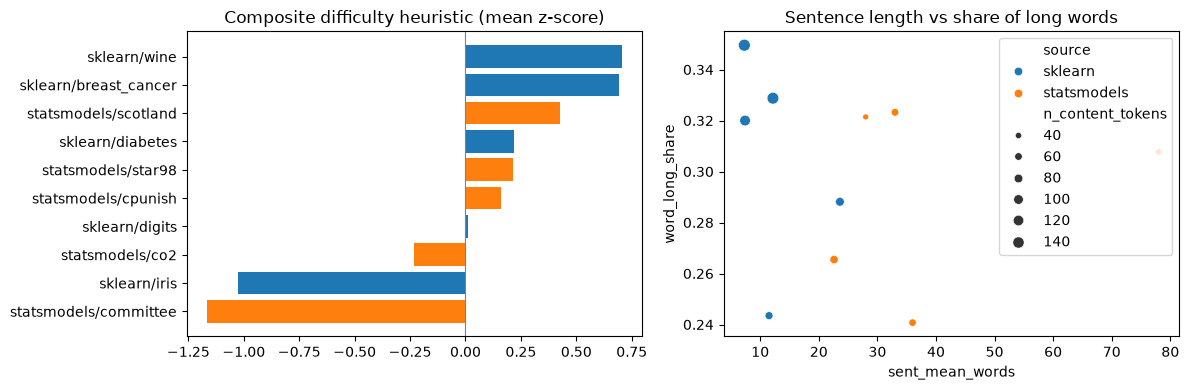

             sent_mean_words  word_mean_len  word_long_share  lex_density
source                                                                   
sklearn               12.393          5.230            0.306        0.658
statsmodels           39.520          5.009            0.292        0.600


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ordered = features.sort_values("difficulty_z")
colors = ordered["source"].map({"sklearn": "tab:blue", "statsmodels": "tab:orange"})
axes[0].barh(ordered.index, ordered["difficulty_z"], color=colors)
axes[0].set_title("Composite difficulty heuristic (mean z-score)")
axes[0].axvline(0, color="grey", lw=0.8)
sns.scatterplot(data=features, x="sent_mean_words", y="word_long_share", hue="source",
                size="n_content_tokens", ax=axes[1])
axes[1].set_title("Sentence length vs share of long words")
plt.tight_layout()
plt.show()
print(features.groupby("source")[cols].mean().round(3))

**Leitura dos resultados:** com apenas 10 documentos e heurísticas simples, o gráfico é **exploratório**. A segmentação de frases por regex é imperfeita em textos com abreviações e listas, e o índice composto não foi validado com leitores reais. O ponto principal aqui é arquitetural: trocar um extrator (por exemplo, por um índice de Flesch de uma biblioteca externa) exige apenas um objeto com `extract()` — sem tocar no pipeline.

## 11. `__subclasshook__`: registro customizado de ABCs

`__subclasshook__` permite que uma ABC decida **sozinha** se uma classe é subclasse dela, inspecionando sua estrutura — é assim que `collections.abc.Iterable` reconhece qualquer classe com `__iter__`. Já `ABC.register(Cls)` declara uma **subclasse virtual** explicitamente.

Diferenças importantes em relação a herdar de verdade:
- Subclasses virtuais **não** herdam métodos concretos da ABC.
- A ABC **não** verifica se os métodos abstratos foram implementados.

In [25]:
class Estimator(ABC):
    """ABC that structurally recognises anything with callable fit + predict."""

    @abstractmethod
    def fit(self, X, y): ...

    @abstractmethod
    def predict(self, X): ...

    @classmethod
    def __subclasshook__(cls, C: type) -> bool | type(NotImplemented):
        if cls is Estimator:
            required = ("fit", "predict")
            if all(any(callable(vars(B).get(m)) for B in C.__mro__) for m in required):
                return True
        return NotImplemented  # fall back to normal inheritance rules


class MajorityClassBaseline:
    """Plain class, no inheritance: predicts the most frequent training class."""

    def fit(self, X, y):
        self.majority_ = Counter(np.asarray(y)).most_common(1)[0][0]
        return self

    def predict(self, X):
        return np.full(len(X), self.majority_)


hook_checks = {
    "LogisticRegression": issubclass(LogisticRegression, Estimator),
    "MajorityClassBaseline": issubclass(MajorityClassBaseline, Estimator),
    "StandardScaler (no predict)": issubclass(StandardScaler, Estimator),
    "StandardScalerLike (no predict)": issubclass(StandardScalerLike, Estimator),
}
print(pd.Series(hook_checks, name="issubclass(..., Estimator)"))

baseline = MajorityClassBaseline().fit(Xb_tr, yb_tr)
print(f"\nBaseline accuracy on breast_cancer test split: {Accuracy()(yb_te, baseline.predict(Xb_te)):.4f}")

LogisticRegression                  True
MajorityClassBaseline               True
StandardScaler (no predict)        False
StandardScalerLike (no predict)    False
Name: issubclass(..., Estimator), dtype: bool

Baseline accuracy on breast_cancer test split: 0.6294


In [26]:
# Explicit virtual subclass registration with ABC.register
class Validator(ABC):
    @abstractmethod
    def validate(self, df: pd.DataFrame) -> list[str]: ...

    def is_valid(self, df: pd.DataFrame) -> bool:  # concrete helper
        return not self.validate(df)


class PenguinRangeCheck:
    """Third-party-style class we cannot (or do not want to) modify."""

    def validate(self, df: pd.DataFrame) -> list[str]:
        issues = []
        if df["body_mass_g"].isna().any():
            issues.append(f"{df['body_mass_g'].isna().sum()} missing body_mass_g values")
        if (df["body_mass_g"] < 2000).any():
            issues.append("body_mass_g below 2000 g")
        return issues


Validator.register(PenguinRangeCheck)
checker = PenguinRangeCheck()
penguins = frames["seaborn:penguins"]
print("isinstance(checker, Validator):", isinstance(checker, Validator))
print("Issues:", checker.validate(penguins))
print("Inherited is_valid()? ", hasattr(checker, "is_valid"))  # False: virtual subclasses inherit nothing

isinstance(checker, Validator): True
Issues: ['2 missing body_mass_g values']
Inherited is_valid()?  False


## 12. Comparação: ABC vs Protocol vs Duck Typing

| Critério | ABC (nominal) | Protocol (estrutural) | Duck typing puro |
|---|---|---|---|
| Precisa herdar? | Sim (ou `register`) | Não | Não |
| Quando o erro aparece | Na **instanciação** | No **checador estático** (mypy/pyright); `isinstance` opcional | Só quando o método é **chamado** |
| Compartilha código | ✅ métodos concretos, *template method* | ❌ (apenas a forma) | ❌ |
| Funciona com classes de terceiros | Só via `register`/`__subclasshook__` | ✅ naturalmente | ✅ |
| Documentação do contrato | Explícita | Explícita | Implícita (docstrings/convenção) |
| Custo em runtime | Baixo | `isinstance` mais lento | Nenhum |
| Melhor uso em DS | Hierarquias **suas**: transformadores, métricas, loaders | Interfaces para **plugar** sklearn/spaCy/funções | Scripts rápidos, protótipos, notebooks exploratórios |

Regra prática: **ABC quando sou dono da hierarquia e quero compartilhar código; Protocol quando quero aceitar qualquer coisa com a forma certa; duck typing quando o custo de formalizar é maior que o benefício.**

A célula abaixo mostra *quando* cada abordagem detecta o mesmo erro (um componente sem `transform`).

In [27]:
class BrokenScalerABC(DataTransformer):        # ABC version: forgot _transform
    def _fit(self, X):
        self.mean_ = X.mean(axis=0)


class BrokenScalerDuck:                         # duck / protocol version: no transform
    def fit(self, X, y=None):
        self.mean_ = np.asarray(X).mean(axis=0)
        return self


timeline = []
try:
    BrokenScalerABC()
except TypeError as exc:
    timeline.append(("ABC", "object creation", str(exc)[:70]))

timeline.append(("Protocol (runtime)", "pipeline construction",
                 f"isinstance(..., FitTransformer) = {isinstance(BrokenScalerDuck(), FitTransformer)}"))

def duck_pipeline(step, X):
    step.fit(X)                      # imagine a long, expensive fit here...
    return step.transform(X)         # ...and only then the failure

try:
    duck_pipeline(BrokenScalerDuck(), X_train)
except AttributeError as exc:
    timeline.append(("Duck typing", "after fit, at call time", str(exc)[:70]))

pd.DataFrame(timeline, columns=["approach", "error detected at", "message"])

,approach,error detected at,message
0,ABC,object creation,Can't instantiate abstract class BrokenScalerA...
1,Protocol (runtime),pipeline construction,"isinstance(..., FitTransformer) = False"
2,Duck typing,"after fit, at call time",'BrokenScalerDuck' object has no attribute 'tr...


## 13. Boas práticas e armadilhas comuns

**Boas práticas**
1. Mantenha ABCs **pequenas** (princípio de segregação de interfaces): `Fittable` e `Transformable` separados são mais reutilizáveis que um `DoEverything`.
2. Coloque **validação compartilhada** na ABC (*template method*) e deixe só a lógica específica nos métodos abstratos.
3. Use `@property` + `@abstractmethod` (nunca `abstractproperty`), com `@abstractmethod` como decorador **mais interno**.
4. Prefira **Protocols** para tipar parâmetros de funções que recebem objetos de bibliotecas externas.
5. Use `@runtime_checkable` apenas quando realmente precisar de `isinstance`; lembre que ele não confere assinaturas.
6. Escreva docstrings nos métodos abstratos: elas **são** a documentação do contrato.
7. Rode `mypy`/`pyright` no CI — Protocols mostram seu valor principalmente na checagem estática.

**Armadilhas** (demonstradas abaixo)
- Achar que o erro aparece na definição da classe (aparece na instanciação).
- Ordem errada dos decoradores (`@abstractmethod` por fora de `@property`).
- Confiar em `isinstance` com protocolos para garantir comportamento.
- Esperar que subclasses virtuais (`register`) herdem métodos.
- Conflito de metaclasses ao combinar `ABC` com outras metaclasses.

In [28]:
pitfalls = {}

# 1) Wrong decorator order: abstractmethod outside property
try:
    class BadOrder(ABC):
        @abstractmethod
        @property
        def name(self): ...
    pitfalls["abstractmethod outside property"] = "no error?!"
except AttributeError as exc:
    pitfalls["abstractmethod outside property"] = f"AttributeError: {exc}"

# 2) Defining an incomplete subclass is silent...
class SilentlyIncomplete(EvaluationMetric):
    name = "incomplete"
    greater_is_better = True

pitfalls["incomplete subclass definition"] = "no error at definition time"
# ...until it is instantiated
try:
    SilentlyIncomplete()
except TypeError as exc:
    pitfalls["incomplete subclass instantiation"] = f"TypeError: {str(exc)[:60]}..."

# 3) Metaclass conflict when mixing ABC with another metaclass
class RegistryMeta(type):
    pass

try:
    class Conflicted(ABC, metaclass=RegistryMeta):
        pass
except TypeError as exc:
    pitfalls["metaclass conflict"] = f"TypeError: {str(exc)[:60]}..."

# Fix: derive the custom metaclass from ABCMeta
class ABCRegistryMeta(ABCMeta):
    registry: dict[str, type] = {}

    def __new__(mcls, name, bases, ns, **kw):
        cls = super().__new__(mcls, name, bases, ns, **kw)
        if not inspect.isabstract(cls):
            mcls.registry[name] = cls
        return cls

class RegisteredBase(metaclass=ABCRegistryMeta):
    @abstractmethod
    def run(self): ...

class ConcreteRun(RegisteredBase):
    def run(self):
        return "ok"

pitfalls["fix: metaclass derived from ABCMeta"] = f"registry = {list(ABCRegistryMeta.registry)}"

# 4) Protocol isinstance does not check signatures (see section 7)
pitfalls["runtime_checkable signature check"] = f"FakeTransformer passes: {isinstance(fake, FitTransformer)}"

pd.Series(pitfalls, name="outcome").to_frame()

,outcome
abstractmethod outside property,AttributeError: attribute '__isabstractmethod_...
incomplete subclass definition,no error at definition time
incomplete subclass instantiation,TypeError: Can't instantiate abstract class Si...
metaclass conflict,TypeError: metaclass conflict: the metaclass o...
fix: metaclass derived from ABCMeta,registry = ['ConcreteRun']
runtime_checkable signature check,FakeTransformer passes: True


In [29]:
# Quick self-checks (lightweight tests) for the components built in this notebook
assert inspect.isabstract(DataTransformer) and not inspect.isabstract(StandardScalerLike)
assert np.allclose(StandardScalerLike().fit_transform(X_iris), StandardScaler().fit_transform(X_iris))
assert run_steps("The Cat and THE dog!") == ["cat", "dog"]
assert Accuracy()([1, 0, 1], [1, 1, 1]) == 2 / 3
assert np.isclose(F1Score()([1, 0, 1, 1], [1, 0, 0, 1]), f1_score([1, 0, 1, 1], [1, 0, 0, 1]))
assert RMSE()([0.0, 0.0], [3.0, 4.0]) == np.sqrt(12.5)
assert RMSE().is_better(0.1, 0.2) and Accuracy().is_better(0.9, 0.8)
assert isinstance(StandardScaler(), FitTransformer) and not isinstance(TextNormalizer(), Fittable)
assert issubclass(MajorityClassBaseline, Estimator) and not issubclass(StandardScaler, Estimator)
assert isinstance(LexicalDensity(StopwordRemover()), FeatureExtractor)
assert SeabornLoader("tips").load().shape == (244, 7)
print("All self-checks passed ✔")

All self-checks passed ✔


## 14. Resumo e próximos passos

### O que aprendi hoje

- **ABCs** (`abc.ABC`, `@abstractmethod`) definem contratos **nominais** e falham cedo, na instanciação. Combinadas com o padrão *template method*, centralizam validação: meus `StandardScalerLike`/`MinMaxScalerLike` reproduziram o scikit-learn no iris escrevendo só a matemática.
- `abstractproperty` está depreciado → use `@property` + `@abstractmethod` (este por dentro).
- Um `TextProcessor` genérico (`Generic[InT, OutT]`) deixa explícito o tipo de entrada/saída de cada etapa de NLP (normalização → tokenização → stopwords).
- **Protocols** (PEP 544) formalizam o duck typing: objetos do scikit-learn satisfazem `Fittable`/`Transformable`/`Scorable` sem herdar nada.
- `@runtime_checkable` habilita `isinstance`, mas só confere **nomes** de membros — um `fit = 42` passa no teste.
- Métricas como classes (`Accuracy`, `F1Score`, `RMSE`) carregam metadados úteis (`greater_is_better`) para seleção de modelos; os valores bateram com o scikit-learn no breast_cancer.
- `DataLoader`s distintos (CSV, JSON, Seaborn) entregam `DataFrame`s validados da mesma forma.
- ABC + Protocol juntos: Protocol para **aceitar** componentes, ABC para **compartilhar** código das minhas implementações — aplicado a um pipeline exploratório de dificuldade textual para leitores de inglês acadêmico.
- `__subclasshook__` e `register()` criam subclasses virtuais — que **não** herdam métodos.

### Conexão com minha trajetória

Em NLP aplicado ao ensino de inglês, terei muitos componentes intercambiáveis (tokenizadores para diferentes variedades, métricas de legibilidade, extratores de features sociolinguísticas). Definir contratos claros torna esses experimentos comparáveis e reprodutíveis — e é exatamente o tipo de fundamento de engenharia de software valorizado em vagas remotas de DS/ML.

### Próximos passos

1. Rodar `mypy --strict` num módulo com esses Protocols para ver a checagem estática em ação.
2. Estudar `sklearn.base.BaseEstimator`/`TransformerMixin` e escrever um transformador compatível com `Pipeline` e `GridSearchCV`.
3. Explorar `typing.Generic` + `Protocol` genéricos (ex.: `Transformable[T]`).
4. Substituir as heurísticas de dificuldade por medidas validadas na literatura (com corpora de aprendizes anotados) na Fase 6 (NLP).

> **Limitações:** todos os resultados vêm de *splits* únicos ou corpus pequeno (10 documentos) e são ilustrativos — não representam rankings de modelos nem níveis de leitura validados.